# 01 · Data understanding and quality assessment
**Synthetic data disclosure:** every record was generated by `scripts/generate_dataset.py` (seed 359). It is
not plant data. This notebook inspects the **raw** file only — nothing is cleaned or modified here, and the
generation log (ground truth) is deliberately not opened.

In [1]:
import sys, pandas as pd
from IPython.display import Image, Markdown, display
sys.path.insert(0, "../scripts")
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
import data_quality_analysis as dqa
raw = dqa.load_raw()
raw.shape

(7354, 29)

## Columns and data types
Loaded as text so nothing is silently converted. `pandas_default_dtype` shows what a naive `read_csv` would infer.

In [2]:
dqa.overview(raw)

,column,pandas_default_dtype,expected,distinct_values
0,Record_ID,str,text/category,7246
1,Pump_ID,str,text/category,116
2,Pump_Type,str,text/category,21
3,Manufacturer,str,text/category,21
4,Installation_Date,str,date,170
5,Observation_Date,str,date,1540
6,Operating_Hours,str,numeric,6874
7,Vibration_mm_s,str,numeric,1088
8,Bearing_Temperature_C,str,numeric,676
9,Seal_Temperature_C,str,numeric,739


In [3]:
raw.head(8)

,Record_ID,Pump_ID,Pump_Type,Manufacturer,Installation_Date,Observation_Date,Operating_Hours,Vibration_mm_s,Bearing_Temperature_C,Seal_Temperature_C,Motor_Temperature_C,Flow_Rate,Suction_Pressure,Discharge_Pressure,Motor_Current,Motor_Speed_RPM,Pressure_Fluctuation,Noise_Level,Observed_Symptoms,Fault_Type,Root_Cause,Supporting_Evidence,Fault_Severity,Diagnostic_Status,Maintenance_Action,Maintenance_Date,Downtime_Hours,Maintenance_Cost,Maintenance_Priority
0,R-000001,P-001,End Suction,Vendor C,2011-06-25,2023-01-02,72726,1.12,53.2,47.1,63.1,130.9,2.08,9.04,52.4,2953,1.5,77.6,No abnormal symptoms,Normal,Not Applicable,All readings within normal operating band,No Fault,No Fault Detected,No action required,,,,Not Applicable
1,R-000717,P-005,End Suction,Vendor D,2018-06-29,2023-01-02,27683,1.98,56.1,51.3,58.4,125.1,1.56,5.96,55.1,1474,1.5,72.7,No abnormal symptoms,Normal,Not Applicable,All readings within normal operating band,No Fault,No Fault Detected,No action required,,,,Not Applicable
2,R-900002,P-032,End Suction,Vendor C,2016-12-20,2025/01/14,54450,4.51,57.2,46.6,65.1,87.2,1.1,6.72,49.0,1476,17.7,77.4,High vibration; Pressure fluctuating; Air bubb...,AIR INGRESS,Leaking suction flange gasket,Vibration 4.5 mm/s; bearing 57 C; Vortex obser...,Medium,Confirmed,Seal suction-side leaks and re-prime,2025-01-24,5.2,651.25,P3 - Medium
3,R-001970,P-012,Vertical Inline,Vendor B,2012-07-04,2023-01-02,61645,6.34,60.6,47.2,69.3,163.8,1.04,5.43,81.5,1473,2.4,81.6,High vibration,Shaft Misalignment,Soft foot / foundation settling,Vibration 6.3 mm/s; bearing 61 C; Coupling ins...,Medium,,No action required,,,,P3 - Medium
4,R-002516,P-015,Vertical Inline,Vendor B,2020-04-18,2023-01-02,18027,2.22,47.7,47.3,161.6 degF,164.5,0.94,3.76,60.3,2951,1.6,75.8,High vibration,Normal,Not Applicable,All readings within normal operating band,No Fault,No Fault Detected,No action required,,,,Not Applicable
5,R-003424,P-020,End Suction,Vendor D,2018-03-01,2023-01-02,33928,1.84,53.5,56.9,74.2,107.4,1.24,6.63,88.9,1475,1.6,74.1,No abnormal symptoms,Normal,Not Applicable,All readings within normal operating band,No Fault,No Fault Detected,No action required,,,,Not Applicable
6,R-005220,P-030,Vertical Inline,Vendor C,2016-07-28,2023-01-02,36614,1.55,49.8,71.0,72.7,129.9,1.24,6.07,37.3,,2.7,79.4,No abnormal symptoms,Mechanical Seal Leakage,Seal flush failure,Vibration 1.6 mm/s; bearing 50 C; Seal faces s...,Low,Confirmed,REPLACE MECHANICAL SEAL,2023-01-13,6.8,2133.72,P4 - Low
7,R-000178,P-002,Multistage,Vendor A,2020-10-03,2023-01-03,15209,2.11,50.4,49.0,64.8,100.9,2.04,17.86,41.5,2950,2.3,77.6,No abnormal symptoms,Normal,Not Applicable,All readings within normal operating band,No Fault,No Fault Detected,No action required,,,,Not Applicable


## Missing values
Empty cells and null-like tokens. Remember: maintenance date/downtime/cost are *structurally* empty when no maintenance happened, and `N/A` in severity/priority means 'not applicable'.

In [4]:
dqa.missing_table(raw).sort_values('missing_%', ascending=False)

,column,empty_cells,null_like_tokens,missing_total,missing_%
27,Maintenance_Cost,6194,0,6194,84.23
26,Downtime_Hours,6193,0,6193,84.21
25,Maintenance_Date,6176,0,6176,83.98
28,Maintenance_Priority,147,145,292,3.97
22,Fault_Severity,108,84,192,2.61
18,Observed_Symptoms,110,51,161,2.19
9,Seal_Temperature_C,131,29,160,2.18
2,Pump_Type,150,0,150,2.04
3,Manufacturer,147,0,147,2.00
10,Motor_Temperature_C,113,30,143,1.94


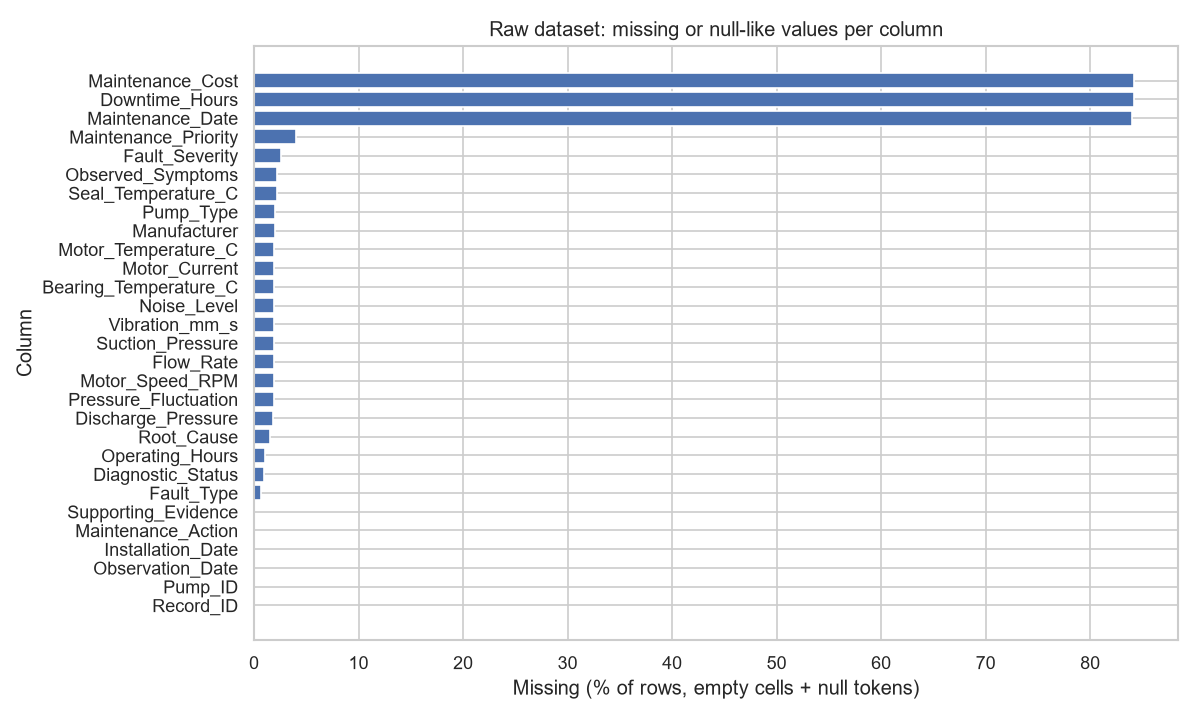

In [5]:
display(Image('../visualizations/01_raw_missing_by_column.png'))

## Duplicates

In [6]:
summary, examples = dqa.duplicate_summary(raw)
display(summary)
examples

{'rows': 7354,
 'exact_duplicate_rows (all copies)': 216,
 'exact_duplicate_rows (redundant copies)': 108,
 'duplicate Record_IDs': 108,
 'same pump + same observation date, not exact copies': 71}

,Record_ID,Pump_ID,Pump_Type,Manufacturer,Installation_Date,Observation_Date,Operating_Hours,Vibration_mm_s,Bearing_Temperature_C,Seal_Temperature_C,Motor_Temperature_C,Flow_Rate,Suction_Pressure,Discharge_Pressure,Motor_Current,Motor_Speed_RPM,Pressure_Fluctuation,Noise_Level,Observed_Symptoms,Fault_Type,Root_Cause,Supporting_Evidence,Fault_Severity,Diagnostic_Status,Maintenance_Action,Maintenance_Date,Downtime_Hours,Maintenance_Cost,Maintenance_Priority
4072,R-900011,P-001,End Suction,Vendor C,25-Jun-2011,11/01/2024,79168,1.99,58.0,,64.8,130.7,2.05,8.91,49.3,2951,2.6,75.3,No abnormal symptoms,NORMAL,Not Applicable,All readings within normal operating band,No Fault,No Fault Detected,No action required,,,,Not Applicable
2515,R-000063,P-001,End Suction,Vendor C,25-Jun-2011,2024-01-11,79168,1.99,58.0,,64.8,130.7,2.05,8.91,49.3,2951,2.6,75.3,No abnormal symptoms,Normal,Not Applicable,All readings within normal operating band,No Fault,No Fault Detected,No action required,,,,Not Applicable
1530,R-000214,P-002,Multistage,Vendor A,2020-10-03,17-Aug-2023,19370,3.78,49.2,52.4,72.3,"59,2",1.81,16.14,32.2,2953,1.8,77.9,Low flow,Pump Blockage,Debris accumulation in impeller,Vibration 3.8 mm/s; bearing 49 C; Scale deposi...,Medium,Suspected,No action required,,,,P3 - Medium
1193,R-900032,P-002,Multistage,Vendor A,2020-10-03,2023/08/17,19370,3.78,49.2,52.4,72.3,"59,2",1.81,16.14,32.2,2953,1.8,77.9,Low flow,PUMP BLOCKAGE,Debris accumulation in impeller,Vibration 3.8 mm/s; bearing 49 C; Scale deposi...,Medium,Suspected,No action required,,,,P3 - Medium
5081,R-000661,P-004,End-Suction,Vendor A,2013-08-25,2025-01-29,71136,1.78,51.4,43.8,63.8,168.0,1.31,5.48,62.6,1475,2.3,77.2,No abnormal symptoms,Normal,Not Applicable,All readings within normal operating band,No Fault,No Fault Detected,Routine preventive maintenance,2025-01-29,2.1,301.15,P4 - Low
5157,R-900014,P-004,End-Suction,Vendor A,2013-08-25,20250129,71136,1.78,51.4,43.8,63.8,168.0,1.31,5.48,62.6,1475,2.3,77.2,No abnormal symptoms,NORMAL,Not Applicable,All readings within normal operating band,No Fault,No Fault Detected,Routine preventive maintenance,2025-01-29,2.1,301.15,P4 - Low


## Value formats in numeric columns
Unit suffixes, comma decimals, thousands separators and error tokens.

In [7]:
patterns, stats, outliers = dqa.numeric_profile(raw)
patterns

,column,plain number,number + unit text,empty,thousands separator,comma decimal,null-like token,currency prefix,non_numeric_examples
0,Operating_Hours,7133,91,76,54,0,0,0,"number + unit text: ['7822 h', '6424 hrs', '81..."
1,Vibration_mm_s,7180,0,110,0,35,29,0,"comma decimal: ['1,85', '1,89', '1,69']; null-..."
2,Bearing_Temperature_C,7074,106,110,0,35,29,0,"number + unit text: ['130.3 °F', '181.4 °F', '..."
3,Seal_Temperature_C,7050,108,131,0,36,29,0,"number + unit text: ['118.0 degF', '169.9F', '..."
4,Motor_Temperature_C,7070,108,113,0,33,30,0,"number + unit text: ['161.6 degF', '150.4 degF..."
5,Flow_Rate,7071,107,110,0,37,29,0,"number + unit text: ['634 gpm', '24.4 L/s', '5..."
6,Suction_Pressure,7067,112,109,0,36,30,0,"number + unit text: ['152 kPa', '17.5 psi', '1..."
7,Discharge_Pressure,7073,109,108,0,35,29,0,"number + unit text: ['106.3 psi', '1246 kPa', ..."
8,Motor_Current,7176,0,113,0,36,29,0,"comma decimal: ['58,7', '29,5', '78,7']; null-..."
9,Motor_Speed_RPM,7216,0,110,0,0,28,0,"null-like token: ['--', 'ERR', 'null']"


## Statistical summary of the values that parse as numbers

In [8]:
stats.round(2)

,column,unit,parseable,mean,std,min,median,max
0,Operating_Hours,h,7133,48228.96,22380.39,3806.00,45306.00,103189.00
1,Vibration_mm_s,mm/s RMS,7180,3.31,4.86,0.40,2.14,250.00
2,Bearing_Temperature_C,°C,7074,56.24,24.64,39.30,52.70,999.00
3,Seal_Temperature_C,°C,7050,51.88,12.07,-99.00,48.80,129.40
4,Motor_Temperature_C,°C,7070,69.51,25.67,54.00,68.10,999.00
5,Flow_Rate,m³/h,7071,169.12,154.33,-330.70,128.00,950.40
6,Suction_Pressure,bar(a),7067,1.64,0.43,0.20,1.72,2.31
7,Discharge_Pressure,bar(a),7073,9.56,118.86,0.49,7.09,9999.00
8,Motor_Current,A,7176,74.74,49.07,0.00,65.20,2112.00
9,Motor_Speed_RPM,rpm,7216,2074.45,806.25,1425.00,1477.00,29520.00


## Outliers: genuine fault signal or data error?
Pooled IQR flags hundreds of values — almost all in fault records. Pooled current/speed outliers in normal records are an artefact of mixing pump sizes.

In [9]:
display(outliers.round(2))
dqa.outliers_by_label(raw)

,column,IQR_fence_low,IQR_fence_high,IQR_outliers,robust_z_gt_3.5,plausible_range,physically_implausible
0,Operating_Hours,-19446.50,117509.50,0,0,0 – 200000,0
1,Vibration_mm_s,-1.91,7.66,564,1237,0.05 – 50,2
2,Bearing_Temperature_C,40.65,65.85,854,780,-10 – 150,4
3,Seal_Temperature_C,37.55,60.35,816,753,-10 – 200,2
4,Motor_Temperature_C,57.15,79.15,230,183,-10 – 180,5
5,Flow_Rate,-45.40,308.60,790,589,0 – 2000,4
6,Suction_Pressure,0.48,2.88,174,26,0.01 – 10,0
7,Discharge_Pressure,2.43,11.84,1117,933,0.01 – 60,1
8,Motor_Current,-14.10,151.70,509,392,0.5 – 400,8
9,Motor_Speed_RPM,-739.00,5165.00,2,3014,300 – 3600,2


,column,pooled IQR: fault/unknown recs,pooled IQR: 'normal' recs,per-pump scaled IQR: 'normal' recs,implausible (any record)
0,Vibration_mm_s,555,9,9,2
1,Bearing_Temperature_C,847,3,2,4
2,Seal_Temperature_C,808,6,6,2
3,Motor_Current,176,328,7,8
4,Motor_Speed_RPM,0,0,62,2
5,Pressure_Fluctuation,608,10,11,4


## Date formats

In [10]:
dqa.date_profile(raw)

,column,ISO YYYY-MM-DD,DD-Mon-YYYY,YYYYMMDD,YYYY/MM/DD,DD/MM/YYYY,empty
0,Installation_Date,7061,94,70,65,64,0.0
1,Observation_Date,6883,100,120,118,133,0.0
2,Maintenance_Date,1108,23,18,12,17,6176.0


## Categorical inconsistencies (spellings grouped by a normalised key)

In [11]:
for c in ['Pump_Type', 'Fault_Type', 'Fault_Severity', 'Maintenance_Priority']:
    display(Markdown(f'**{c}**'), dqa.category_variants(raw, c, top=15))

**Pump_Type**

,variants,n_variants,n
1,'END SUCTION' · 'End Suction' · 'End-Suction' ...,5,3577
6,'VERTICAL INLINE' · 'Vertical In-line' · 'Vert...,4,1262
5,'SPLIT CASE' · 'Split Case' · 'Split-case' · '...,4,1256
4,'MULTISTAGE' · 'Multi Stage' · 'Multi-stage' ·...,5,1091
0,'',1,150
3,'Inline',1,11
2,'Horizontal split case',1,7


**Fault_Type**

,variants,n_variants,n
37,'NORMAL' · 'Normal' · 'normal',3,4431
6,'BEARING FAILURE' · 'Bearing Failure' · 'Beari...,4,645
29,'MECHANICAL SEAL LEAKAGE' · 'Mechanical Seal L...,2,562
24,'IMPELLER DAMAGE' · 'Impeller Damage' · 'impel...,3,265
12,' Cavitation' · 'CAVITATION' · 'Cavitation' · ...,4,243
44,'SHAFT MISALIGNMENT' · 'Shaft Misalignment' · ...,4,198
17,'DISCHARGE RESTRICTION' · 'Discharge Restricti...,3,157
35,'MOTOR FAULT' · 'Motor Fault' · 'motor fault',3,156
4,'AIR INGRESS' · 'Air Ingress' · 'air ingress',3,151
40,'PUMP BLOCKAGE' · 'Pump Blockage' · 'pump bloc...,3,148


**Fault_Severity**

,variants,n_variants,n
16,'No Fault' · 'no fault',2,4266
14,'Medium' · 'medium',2,1088
9,'HIGH' · 'High' · 'high',3,727
11,'LOW' · 'Low' · 'low',3,675
7,'Critical' · 'critical',2,277
0,'',1,108
1,'0',1,55
15,'N/A',1,44
17,'none',1,40
3,'2',1,13


**Maintenance_Priority**

,variants,n_variants,n
6,'Not Applicable',1,4128
12,'P3 - Medium',1,1086
14,'P4 - Low',1,777
10,'P2 - High',1,655
8,'P1 - Emergency',1,337
0,'' · '-',2,193
5,'NA' · 'n/a',2,99
17,'Priority 3',1,16
3,'low',1,9
4,'medium',1,9


## Free-text symptoms

In [12]:
seps, tokens = dqa.symptom_profile(raw)
display(seps)
tokens.head(30)

,separator,rows
0,'; ',1550
1,"', '",40
2,' | ',29
3,' / ',47
4,' and ',44


Observed_Symptoms
no abnormal symptoms        4172
high vibration              1344
low flow                     590
visible seal leakage         470
grinding noise               459
pressure fluctuating         362
coupling vibration           322
high bearing temperature     310
low suction pressure         282
high seal temperature        281
high noise level             275
low discharge pressure       191
crackling noise              169
high discharge pressure      150
rapid temperature rise       145
air bubbles in discharge     113
high motor temperature       105
motor speed unstable          96
loss of prime                 89
no flow                       86
none                          84
normal                        81
nil                           80
no issues                     66
high motor current            58
vibration high                49
excessive vibration           27
high vib                      25
grinding sound                22
leak at seal             

The full write-up is `reports/data_quality_report.md` (regenerate with `python scripts/data_quality_analysis.py`).